In [6]:
import pandas as pd

df = pd.read_csv("../data/cleaned_house_data.csv")

df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [7]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (506, 14)
Missing values: CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64
Duplicate rows: 0


In [8]:
# Prepare the data for modeling
y = df["MEDV"]
X = df.drop(columns=["MEDV"])

In [9]:
# Split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [10]:
# Scale the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
# Train a linear regression model
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
y_pred_linear = linear_model.predict(X_test_scaled)

In [12]:
print("First 10 predictions:")
print(y_pred_linear[:10])

print("\nFirst 10 actual values:")
print(y_test.values[:10])

First 10 predictions:
[29.51914467 36.29346423 15.20858764 25.27834766 18.18693394 23.4630735
 17.54300504 13.91657753 22.86651308 20.84817427]

First 10 actual values:
[23.6 32.4 13.6 22.8 16.1 20.  17.8 14.  19.6 16.8]


In [13]:
# Evaluate the model
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred_linear)
r2 = r2_score(y_test, y_pred_linear)

print("linear regression model evaluation:")
print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")

linear regression model evaluation:
Mean Squared Error: 23.118735856923514
R-squared: 0.684746444808648


In [14]:
# Train a decision tree regression model
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train_scaled, y_train)
y_pred_tree = tree_model.predict(X_test_scaled)

In [15]:
#Evaluate the decision tree model
mse_tree = mean_squared_error(y_test, y_pred_tree)
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Regression Results")
print("MSE:", mse_tree)
print("R²:", r2_tree)

Decision Tree Regression Results
MSE: 16.685294117647064
R²: 0.7724746576735373


In [16]:
# Train a random forest regression model
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    random_state=42
)
forest_model.fit(X_train_scaled, y_train)
y_pred_forest = forest_model.predict(X_test_scaled)



In [17]:
# Evaluate the decision tree model
mse_forest = mean_squared_error(y_test, y_pred_forest)
r2_forest = r2_score(y_test, y_pred_forest)

print("Random Forest Regression Results")
print("MSE:", mse_forest)
print("R²:", r2_forest)

Random Forest Regression Results
MSE: 8.325181323529412
R²: 0.8864754964934943


In [18]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MSE": [
        mse,
        mse_tree,
        mse_forest
    ],
    "R²": [
        r2,
        r2_tree,
        r2_forest
    ]
})

results

,Model,MSE,R²
0,Linear Regression,23.118736,0.684746
1,Decision Tree,16.685294,0.772475
2,Random Forest,8.325181,0.886475


In [19]:
best_model = results.loc[results["R²"].idxmax()]

print("Best Model:", best_model["Model"])
print("MSE:", best_model["MSE"])
print("R²:", best_model["R²"])

Best Model: Random Forest
MSE: 8.325181323529412
R²: 0.8864754964934943


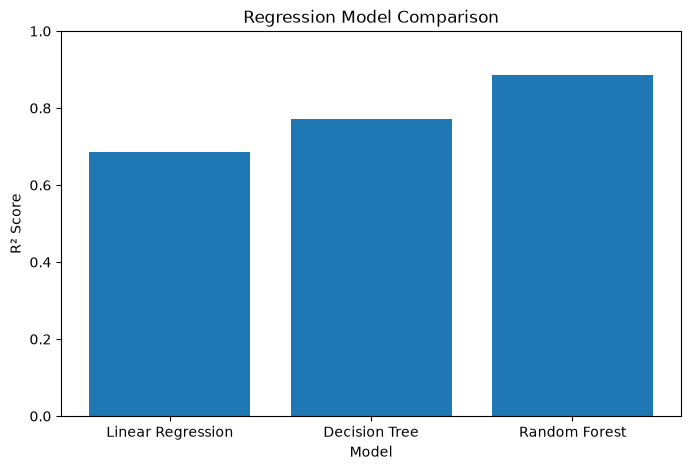

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["R²"])

plt.ylabel("R² Score")
plt.xlabel("Model")
plt.title("Regression Model Comparison")

plt.ylim(0, 1)
plt.show()

### Model Comparison

Three regression models were trained and evaluated using the same training and testing datasets.

Linear Regression achieved an MSE of 23.12 and an R² score of 0.685, providing a baseline for comparison.

Decision Tree Regression improved performance, achieving an MSE of 16.69 and an R² score of 0.772.

Random Forest Regression produced the strongest results, with an MSE of 8.33 and an R² score of 0.886. This indicates that the Random Forest model explained approximately 88.6% of the variation in median house values on the test set.

Based on the evaluation metrics, Random Forest Regression was the best-performing model among the three models tested.

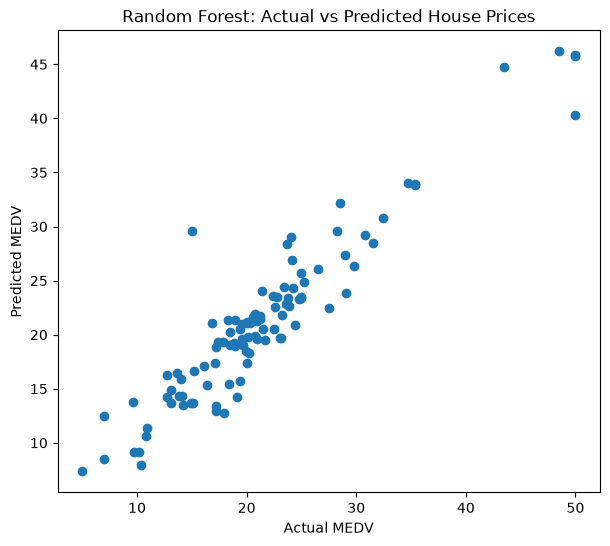

In [21]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred_forest)

plt.xlabel("Actual MEDV")
plt.ylabel("Predicted MEDV")
plt.title("Random Forest: Actual vs Predicted House Prices")

plt.show()

Random Forest performed substantially better than both Linear Regression and Decision Tree Regression, achieving the lowest MSE (8.33) and highest R² (0.886). The results suggest that the relationships between the housing features and median house value are not completely captured by a simple linear model. The ensemble approach of Random Forest was better able to model these relationships on the test data.